# T20 — Brain Tumor MRI Classification — TensorFlow

**Role 2 — Ahmed Refaat** · Framework: TensorFlow/Keras  
**Repo:** `sayfeldinn/t20-brain-tumor-detection`  
**Deadline:** Mon Oct 26, 10:00 AM  

### Rules (do not change)
- Seed = 42; Batch = 32; Max epochs = 15; Early-stop patience = 3 on val_loss
- `split_manifest.csv` is the single source of truth — **never resplit**
- Test set evaluated **once**, on the final chosen model only
- Augmentation: ±10° rotation, ±10% shift, 0.9–1.1 zoom, brightness/contrast 0.9–1.1; **no vertical flip, no hue/sat**
- Notebook pushed **with outputs saved**

### Colab path prefix rule
After cloning below, manifest paths are prefixed with `/content/t20-brain-tumor-detection/`.

## 0 — Colab Setup: Clone the repo

In [ ]:

import os
import subprocess
from google.colab import userdata

# Get your token securely from Colab Secrets
TOKEN = userdata.get("GITHUB_TOKEN")

if not TOKEN:
    raise ValueError(
        "GITHUB_TOKEN is missing. Add it in Colab Secrets first."
    )

REPO_URL = (
    f"https://x-access-token:{TOKEN}"
    "@github.com/sayfeldinn/t20-brain-tumor-detection.git"
)
REPO_DIR = "/content/t20-brain-tumor-detection"

# Clone the repo or update the existing copy
if not os.path.exists(os.path.join(REPO_DIR, ".git")):
    subprocess.run(
        ["git", "clone", REPO_URL, REPO_DIR],
        check=True
    )
    print("Repository cloned successfully.")
else:
    # Update the remote URL in memory for this command only
    subprocess.run(
        ["git", "-c", f"remote.origin.url={REPO_URL}",
         "-C", REPO_DIR, "pull"],
        check=True
    )
    print("Repository updated successfully.")

# Switch to the project directory
os.chdir(REPO_DIR)
print("Working directory:", os.getcwd())


Repository cloned successfully.
Working directory: /content/t20-brain-tumor-detection


## CELL A — Constants (shared, verbatim)

In [ ]:
# ============================================================
# CELL A — constants (identical in both notebooks)
# ============================================================
CLASSES = ["glioma", "meningioma", "notumor", "pituitary"]   # index 0..3, do not change
SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 32
# Split manifest: columns path,label,split with split in {train,val,test}.
# Manifest itself is committed at split_manifest.csv — never resplit.

## CELL B — Seeding (TensorFlow, verbatim)

In [ ]:
# ============================================================
# CELL B — seeding
# ------------------------------------------------------------
# TensorFlow:
import os, random
import numpy as np
import tensorflow as tf
def seed_everything(seed=SEED):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
seed_everything()

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {tf.config.list_physical_devices('GPU')}")

TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## CELL C — Manifest Loading (verbatim + Colab prefix)

In [ ]:
# ============================================================
# CELL C — manifest loading (paths are relative to T20/ repo root)
# ------------------------------------------------------------
# The dataset (data/) and the manifest are both IN THE REPO — after
# `git clone`, paths just work if the notebook runs from the repo root.
# On Colab: clone the repo (TEAM_PLAN.md §6) and prefix once, e.g.
#   df["path"] = "/content/t20-brain-tumor-detection/" + df["path"]
# Never re-generate the split.
import pandas as pd
df = pd.read_csv("split_manifest.csv")

# Colab prefix — paths in the manifest are relative to repo root
df["path"] = "/content/t20-brain-tumor-detection/" + df["path"]

train_df = df[df.split == "train"].reset_index(drop=True)
val_df   = df[df.split == "val"].reset_index(drop=True)
test_df  = df[df.split == "test"].reset_index(drop=True)

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")
print(train_df.groupby('label').size())

Train: 4760  Val: 840  Test: 1600
label
glioma        1190
meningioma    1190
notumor       1190
pituitary     1190
dtype: int64


## CELL D — Augmentation Spec (TensorFlow implementation)

In [ ]:
# ============================================================
# CELL D — augmentation spec (train only; val/test: resize + normalize only)
# ------------------------------------------------------------
# PARAMETERS (same semantics in both frameworks):
#   - rotation: +/-10 degrees
#   - translation: +/-10% of width/height
#   - zoom/scale: 0.9 .. 1.1
#   - brightness: 0.9 .. 1.1 ; contrast: 0.9 .. 1.1
#   - horizontal flip: NOT applied (left/right asymmetry in MRI is not
#     guaranteed to be invariant) — if a run enables it, justify in report
#   - FORBIDDEN: vertical flip, hue/saturation changes, heavy distortions
#   - val/test: no augmentation, only resize to 224x224 + native preprocessing
# TensorFlow equivalent: RandomRotation(10/360), RandomTranslation(0.1,0.1),
#   RandomZoom(0.1), RandomBrightness(0.1), RandomContrast(0.1), no RandomFlip

# TensorFlow augmentation layers (train pipeline only)
train_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(factor=10/360, seed=SEED),
    tf.keras.layers.RandomTranslation(height_factor=0.1, width_factor=0.1, seed=SEED),
    tf.keras.layers.RandomZoom(height_factor=(-0.1, 0.1), seed=SEED),
    tf.keras.layers.RandomBrightness(factor=0.1, seed=SEED),
    tf.keras.layers.RandomContrast(factor=0.1, seed=SEED),
    # NO RandomFlip — MRI left/right asymmetry is clinically significant
], name="train_augmentation")

print("Augmentation layers defined (train only).")

Augmentation layers defined (train only).


## CELL E — Metrics Function (verbatim)

In [ ]:
# ============================================================
# CELL E — metrics function (copy verbatim into both notebooks)
# ------------------------------------------------------------
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
def evaluate_predictions(y_true, y_pred, classes=CLASSES, title=""):
    """y_true/y_pred: integer labels 0..3. Prints report; returns dict + figs."""
    acc = accuracy_score(y_true, y_pred)
    rep = classification_report(y_true, y_pred, target_names=classes, digits=4,
                                output_dict=True, zero_division=0)
    print(f"=== {title} ===")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_true, y_pred, target_names=classes,
                                digits=4, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right")
    ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    for i in range(len(classes)):
        for j in range(len(classes)):
            ax.text(j, i, cm[i, j], ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_title(f"{title} confusion matrix")
    fig.tight_layout()
    return {"accuracy": acc,
            "macro_precision": rep["macro avg"]["precision"],
            "macro_recall": rep["macro avg"]["recall"],
            "macro_f1": rep["macro avg"]["f1-score"],
            "per_class": {c: rep[c] for c in classes},
            "confusion_matrix": cm.tolist()}

## CELL F — Timing / Memory Logging Helper (TensorFlow, verbatim)

In [ ]:
# ============================================================
# CELL F — timing / memory logging helper
# ------------------------------------------------------------
# TensorFlow:
import time, tensorflow as tf
def gpu_mem_mb():
    try: return tf.config.experimental.get_memory_info("GPU:0")["peak_bytes"] // 1024**2
    except Exception: return 0
def reset_gpu_mem():
    try: tf.config.experimental.reset_memory_stats("GPU:0")
    except Exception: pass
# Per-run record (append one dict per run, dump to results/metrics_<fw>.json):
# {framework, architecture, strategy, epochs_run, seconds_per_epoch,
#  total_train_seconds, peak_gpu_memory_mb, trainable_params, total_params,
#  saved_model_size_mb, best_val_loss, best_val_acc}

import json, os

all_run_metrics = []  # accumulate across R1..R4

def log_run_metrics(run_id, arch, strategy, history, model, t_total, t_per_epoch):
    """Extract and store per-run metrics."""
    best_val_loss_idx = np.argmin(history.history["val_loss"])
    total_params = model.count_params()
    trainable_params = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
    record = {
        "framework": "tensorflow",
        "architecture": arch,
        "strategy": strategy,
        "run_id": run_id,
        "epochs_run": len(history.history["val_loss"]),
        "seconds_per_epoch": round(t_per_epoch, 2),
        "total_train_seconds": round(t_total, 2),
        "peak_gpu_memory_mb": gpu_mem_mb(),
        "trainable_params": int(trainable_params),
        "total_params": int(total_params),
        "saved_model_size_mb": None,
        "best_val_loss": round(history.history["val_loss"][best_val_loss_idx], 6),
        "best_val_acc": round(history.history["val_accuracy"][best_val_loss_idx], 6),
        "notes": ""
    }
    all_run_metrics.append(record)
    print(f"[{run_id}] best_val_loss={record['best_val_loss']:.4f}  best_val_acc={record['best_val_acc']:.4f}  epochs_run={record['epochs_run']}")
    return record

def save_metrics_json(final_model_metrics=None):
    """Write results/metrics_tensorflow.json."""
    payload = {
        "_template": "Role 1 collects ONE entry per run (R1..R5) per framework, from notebook outputs. Fields below are the plan's metrics log.",
        "runs": all_run_metrics,
        "final_model": final_model_metrics or {
            "selected_run": None, "test_accuracy": None,
            "macro_precision": None, "macro_recall": None, "macro_f1": None,
            "per_class": {}, "confusion_matrix": [], "gradcam_done": False, "model_file_mb": None
        }
    }
    os.makedirs("results", exist_ok=True)
    with open("results/metrics_tensorflow.json", "w") as f:
        json.dump(payload, f, indent=2)
    print("Saved results/metrics_tensorflow.json")

print("CELL F ready.")

CELL F ready.


## CELL G — GradCAM Test Paths (verbatim)

In [ ]:
# ============================================================
# CELL G — fixed GradCAM test images (same for both models)
# ------------------------------------------------------------
# 6 fixed images + 1 misclassified image (added after final models exist).
GRADCAM_TEST_PATHS = [
    "data/Testing/glioma/Te-gl_100.jpg",
    "data/Testing/meningioma/Te-aug-me_100.jpg",
    "data/Testing/notumor/Te-no_100.jpg",
    "data/Testing/pituitary/Te-pi_100.jpg",
    "data/Testing/glioma/Te-gl_109.jpg",
    "data/Testing/pituitary/Te-pi_109.jpg",
    # ROLE 1 WILL APPEND ONE MISCLASSIFIED TEST IMAGE HERE after the final
    # models exist (same path for both frameworks' notebooks).
]
# GradCAM target layers:
#   PyTorch:    ResNet50 model.layer4[-1] ; EfficientNet-B0 model.features[-1]
#   TensorFlow: ResNet50 "conv5_block3_out" ; EfficientNetB0 "top_activation"

# Prefix paths for Colab
GRADCAM_TEST_PATHS = ["/content/t20-brain-tumor-detection/" + p for p in GRADCAM_TEST_PATHS]
print("CELL G — GradCAM paths set.")
for p in GRADCAM_TEST_PATHS:
    print(" ", p)

CELL G — GradCAM paths set.
  /content/t20-brain-tumor-detection/data/Testing/glioma/Te-gl_100.jpg
  /content/t20-brain-tumor-detection/data/Testing/meningioma/Te-aug-me_100.jpg
  /content/t20-brain-tumor-detection/data/Testing/notumor/Te-no_100.jpg
  /content/t20-brain-tumor-detection/data/Testing/pituitary/Te-pi_100.jpg
  /content/t20-brain-tumor-detection/data/Testing/glioma/Te-gl_109.jpg
  /content/t20-brain-tumor-detection/data/Testing/pituitary/Te-pi_109.jpg


## 1 — tf.data Pipeline

In [ ]:
# tf.data pipeline
CLASS_TO_IDX = {c: i for i, c in enumerate(CLASSES)}
AUTOTUNE = tf.data.AUTOTUNE

def load_and_resize(path, label):
    """Read JPEG/PNG, convert to RGB (handles grayscale), resize to 224x224."""
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMAGE_SIZE, IMAGE_SIZE])
    img = tf.cast(img, tf.float32)  # 0..255 float; backbone preprocessing applied inside model
    return img, label

def make_dataset(dataframe, augment=False, shuffle=False):
    paths  = dataframe["path"].values
    labels = dataframe["label"].map(CLASS_TO_IDX).values.astype("int32")
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED)
    ds = ds.map(load_and_resize, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    if augment:
        ds = ds.map(lambda x, y: (train_augmentation(x, training=True), y),
                    num_parallel_calls=AUTOTUNE)
    ds = ds.prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(train_df, augment=True, shuffle=True)
val_ds   = make_dataset(val_df,   augment=False, shuffle=False)
test_ds  = make_dataset(test_df,  augment=False, shuffle=False)

print("Datasets created.")
for x, y in train_ds.take(1):
    print(f"  Batch shape: {x.shape}  Labels: {y.numpy()[:8]}")

Datasets created.
  Batch shape: (32, 224, 224, 3)  Labels: [3 2 2 2 3 0 1 2]


## 2 — Model Builder

In [ ]:
# Model builder
from tensorflow.keras import applications, layers, models, optimizers, callbacks

def build_model(arch="resnet50", freeze_base=True, learning_rate=1e-3):
    """
    Builds a 4-class classifier with preprocessing INSIDE the model.
    arch: 'resnet50' | 'efficientnetb0'
    freeze_base: if True -> head-only training; if False -> fine-tune
    Preprocessing contract:
      - ResNet50: preprocess_input layer (scales 0..255)
      - EfficientNetB0: raw 0..255 input (Rescaling lives inside the EfficientNet model)
    Saved .keras takes 224x224x3 RGB float32 0..255.
    """
    seed_everything()  # re-seed before each model build

    inp = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, 3), name="input_image")

    if arch == "resnet50":
        # Preprocessing inside model
        x = layers.Lambda(
            lambda t: applications.resnet.preprocess_input(t),
            name="resnet_preprocess"
        )(inp)
        base = applications.ResNet50(
            weights="imagenet", include_top=False,
            input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
        )
        target_layer = "conv5_block3_out"
    elif arch == "efficientnetb0":
        # EfficientNetB0 has Rescaling(1./255) already inside; just pass raw 0..255
        x = inp
        base = applications.EfficientNetB0(
            weights="imagenet", include_top=False,
            input_shape=(IMAGE_SIZE, IMAGE_SIZE, 3)
        )
        target_layer = "top_activation"
    else:
        raise ValueError(f"Unknown arch: {arch}")

    base.trainable = not freeze_base

    # Call base with training=False to keep BatchNorm in inference mode during fine-tune
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D(name="gap")(x)
    x = layers.Dropout(0.3, seed=SEED, name="dropout")(x)
    out = layers.Dense(len(CLASSES), activation="softmax", name="predictions")(x)

    model = models.Model(inputs=inp, outputs=out,
                         name=f"{arch}_{'frozen' if freeze_base else 'finetune'}")
    model.compile(
        optimizer=optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    return model, base, target_layer

print("Model builder ready.")

Model builder ready.


## 3 — Training Helper & Loss Curve Plotter

In [ ]:
# Training helper
MAX_EPOCHS = 15
PATIENCE   = 3

def train_run(run_id, arch, freeze_base, learning_rate=1e-3):
    strategy_label = "frozen_backbone" if freeze_base else f"finetune_lr{learning_rate:.0e}"
    print(f"\n{'='*60}")
    print(f"Run {run_id}: arch={arch}  freeze={freeze_base}  lr={learning_rate}")
    print(f"{'='*60}")

    reset_gpu_mem()
    model, base, target_layer = build_model(arch, freeze_base, learning_rate)
    model.summary(show_trainable=True)

    cb_early = callbacks.EarlyStopping(
        monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1
    )

    t0 = time.time()
    history = model.fit(
        train_ds, validation_data=val_ds,
        epochs=MAX_EPOCHS,
        callbacks=[cb_early],
        verbose=1
    )
    t_total = time.time() - t0
    n_epochs = len(history.history["val_loss"])
    t_per_epoch = t_total / n_epochs

    record = log_run_metrics(run_id, arch, strategy_label, history, model, t_total, t_per_epoch)
    plot_loss_curve(history, run_id)
    return model, history, record, target_layer

def plot_loss_curve(history, run_id):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history.history["loss"],     label="train_loss")
    axes[0].plot(history.history["val_loss"], label="val_loss")
    axes[0].set_title(f"{run_id} - Loss")
    axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history.history["accuracy"],     label="train_acc")
    axes[1].plot(history.history["val_accuracy"], label="val_acc")
    axes[1].set_title(f"{run_id} - Accuracy")
    axes[1].set_xlabel("Epoch"); axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.suptitle(f"Run {run_id}", fontsize=13)
    plt.tight_layout()
    plt.show()

print("Training helpers ready.")

Training helpers ready.


## 4 — R1: ResNet50, Frozen Backbone


Run R1: arch=resnet50  freeze=True  lr=0.001
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "resnet50_frozen"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_image (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet_preprocess (Lambda)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet50 (Functional)       │ (None, 7, 7, 2048)    │ 23,587,712 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ gap                         │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ predictions (Dense)         │ (None, 4)             │      8,196 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 8,196 (32.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

Epoch 1/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 83s 463ms/step - accuracy: 0.7256 - loss: 0.7050 - val_accuracy: 0.8607 - val_loss: 0.3713
Epoch 2/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 63s 387ms/step - accuracy: 0.8389 - loss: 0.4228 - val_accuracy: 0.8762 - val_loss: 0.3132
Epoch 3/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 58s 386ms/step - accuracy: 0.8685 - loss: 0.3656 - val_accuracy: 0.8429 - val_loss: 0.3954
Epoch 4/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 58s 387ms/step - accuracy: 0.8664 - loss: 0.3428 - val_accuracy: 0.8429 - val_loss: 0.3791
Epoch 5/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 81s 380ms/step - accuracy: 0.8777 - loss: 0.3168 - val_accuracy: 0.9036 - val_loss: 0.2706
Epoch 6/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 82s 383ms/step - accuracy: 0.8836 - loss: 0.3052 - val_accuracy: 0.8869 - val_loss: 0.2677
Epoch 7/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 59s 395ms/step - accuracy: 0.8882 - loss: 0.2931 - val_accuracy: 0.8500 - val_loss: 0.3725
Epoch 8/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 59s 393ms/step - accuracy: 0.8983 - loss: 0

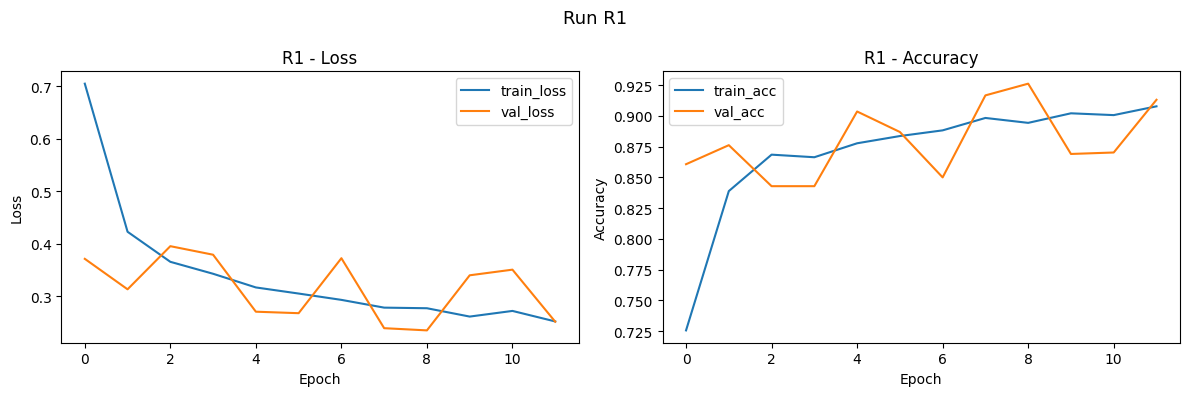

In [ ]:
model_r1, history_r1, record_r1, target_r1 = train_run(
    run_id="R1", arch="resnet50", freeze_base=True, learning_rate=1e-3
)

## 5 — R2: ResNet50, Fine-tune Last Block (LR 1e-5)

R2 - Fine-tuning ResNet50 (unfreeze conv5_block3)...


Model: "resnet50_finetune"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_image (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet_preprocess (Lambda)  │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ resnet50 (Functional)       │ (None, 7, 7, 2048)    │ 23,587,712 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ gap                         │ (None, 2048)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 2048)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ predictions (Dense)         │ (None, 4)             │      8,196 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 23,595,908 (90.01 MB)

 Trainable params: 4,473,860 (17.07 MB)

 Non-trainable params: 19,122,048 (72.94 MB)

Epoch 1/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 86s 471ms/step - accuracy: 0.5061 - loss: 1.2073 - val_accuracy: 0.7667 - val_loss: 0.6568
Epoch 2/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 59s 392ms/step - accuracy: 0.7643 - loss: 0.6281 - val_accuracy: 0.8452 - val_loss: 0.4217
Epoch 3/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 81s 385ms/step - accuracy: 0.8311 - loss: 0.4676 - val_accuracy: 0.8679 - val_loss: 0.3474
Epoch 4/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 58s 388ms/step - accuracy: 0.8597 - loss: 0.3817 - val_accuracy: 0.8869 - val_loss: 0.3145
Epoch 5/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 59s 390ms/step - accuracy: 0.8807 - loss: 0.3217 - val_accuracy: 0.8988 - val_loss: 0.2741
Epoch 6/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 59s 391ms/step - accuracy: 0.8880 - loss: 0.2977 - val_accuracy: 0.9119 - val_loss: 0.2474
Epoch 7/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 58s 388ms/step - accuracy: 0.9032 - loss: 0.2653 - val_accuracy: 0.9250 - val_loss: 0.2284
Epoch 8/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 59s 394ms/step - accuracy: 0.9082 - loss: 0

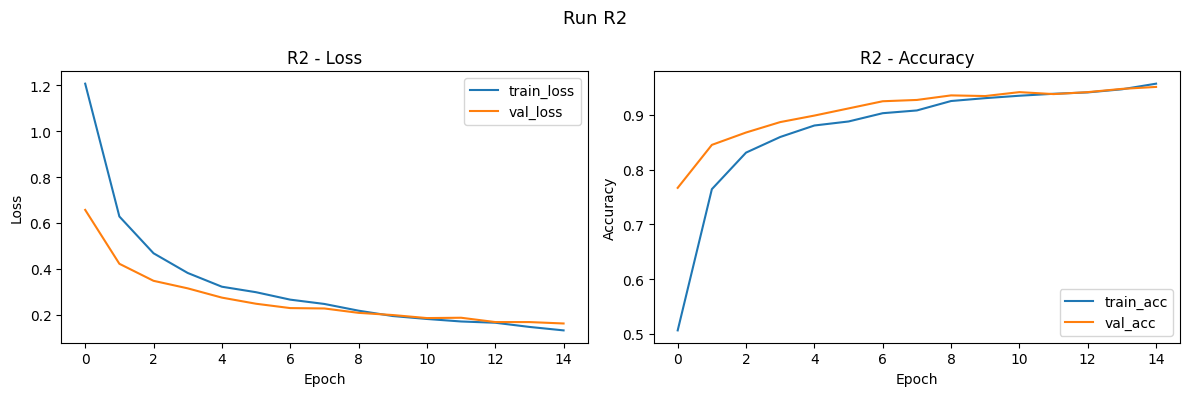

In [ ]:
# Fine-tune: unfreeze last conv block of ResNet50 (conv5_block3) at low LR
print("R2 - Fine-tuning ResNet50 (unfreeze conv5_block3)...")

model_r2, base_r2, target_r2 = build_model("resnet50", freeze_base=False, learning_rate=1e-5)

# Freeze all layers EXCEPT conv5_block3 and head
for layer in model_r2.layers:
    layer.trainable = False
for layer in model_r2.layers:
    if hasattr(layer, 'layers'):   # the base ResNet model
        for sublayer in layer.layers:
            if 'conv5_block3' in sublayer.name:
                sublayer.trainable = True
# Always keep head trainable
for lname in ['gap', 'dropout', 'predictions']:
    try: model_r2.get_layer(lname).trainable = True
    except: pass

model_r2.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model_r2.summary(show_trainable=True)

reset_gpu_mem()
cb_early_r2 = callbacks.EarlyStopping(
    monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1
)
t0 = time.time()
history_r2 = model_r2.fit(
    train_ds, validation_data=val_ds,
    epochs=MAX_EPOCHS, callbacks=[cb_early_r2], verbose=1
)
t_total_r2 = time.time() - t0
record_r2 = log_run_metrics("R2", "ResNet50", "finetune_conv5block3_lr1e-5",
                             history_r2, model_r2, t_total_r2,
                             t_total_r2 / len(history_r2.history["val_loss"]))
plot_loss_curve(history_r2, "R2")

## 6 — R3: EfficientNetB0, Frozen Backbone


Run R3: arch=efficientnetb0  freeze=True  lr=0.001
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "efficientnetb0_frozen"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_image (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   N   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ gap                         │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ predictions (Dense)         │ (None, 4)             │      5,124 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

Epoch 1/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 110s 557ms/step - accuracy: 0.7153 - loss: 0.7535 - val_accuracy: 0.7345 - val_loss: 0.6505
Epoch 2/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 376ms/step - accuracy: 0.8189 - loss: 0.4978 - val_accuracy: 0.7607 - val_loss: 0.5998
Epoch 3/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 372ms/step - accuracy: 0.8511 - loss: 0.4250 - val_accuracy: 0.7488 - val_loss: 0.6203
Epoch 4/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 374ms/step - accuracy: 0.8628 - loss: 0.3936 - val_accuracy: 0.7571 - val_loss: 0.5763
Epoch 5/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 82s 372ms/step - accuracy: 0.8641 - loss: 0.3695 - val_accuracy: 0.7940 - val_loss: 0.5339
Epoch 6/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 82s 370ms/step - accuracy: 0.8668 - loss: 0.3555 - val_accuracy: 0.7726 - val_loss: 0.6057
Epoch 7/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 377ms/step - accuracy: 0.8697 - loss: 0.3491 - val_accuracy: 0.7821 - val_loss: 0.5658
Epoch 8/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 378ms/step - accuracy: 0.8645 - loss: 

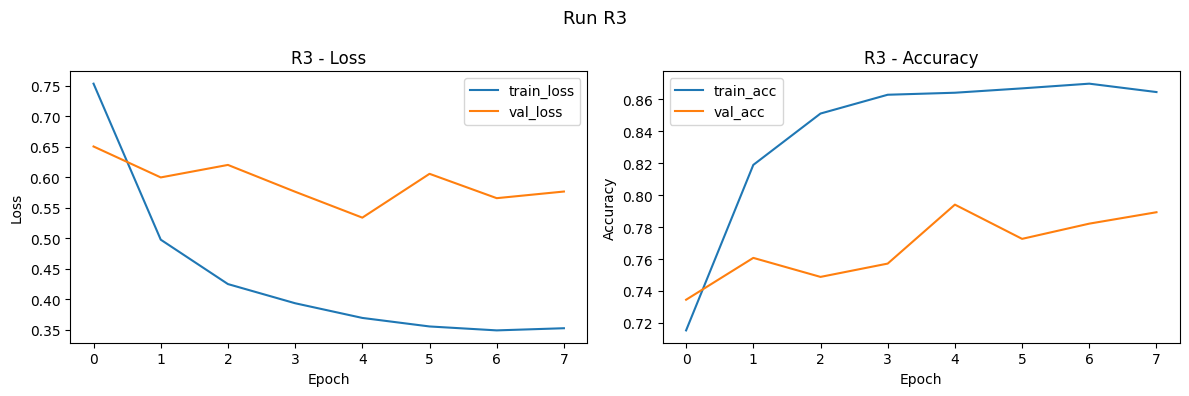

In [ ]:
model_r3, history_r3, record_r3, target_r3 = train_run(
    run_id="R3", arch="efficientnetb0", freeze_base=True, learning_rate=1e-3
)

## 7 — R4: EfficientNetB0, Fine-tune Top Layers (LR 1e-5)

R4 - Fine-tuning EfficientNetB0 (top ~20 layers)...


Model: "efficientnetb0_finetune"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━┓
┃ Layer (type)                ┃ Output Shape          ┃    Param # ┃ Trai… ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━┩
│ input_image (InputLayer)    │ (None, 224, 224, 3)   │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ efficientnetb0 (Functional) │ (None, 7, 7, 1280)    │  4,049,571 │   Y   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ gap                         │ (None, 1280)          │          0 │   -   │
│ (GlobalAveragePooling2D)    │                       │            │       │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ dropout (Dropout)           │ (None, 1280)          │          0 │   -   │
├─────────────────────────────┼───────────────────────┼────────────┼───────┤
│ predictions (Dense)         │ (None, 4)             │      5,124 │   Y   │
└─────────────────────────────┴───────────────────────┴────────────┴───────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 1,356,084 (5.17 MB)

 Non-trainable params: 2,698,611 (10.29 MB)

Epoch 1/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 107s 538ms/step - accuracy: 0.4431 - loss: 1.2448 - val_accuracy: 0.6536 - val_loss: 1.0420
Epoch 2/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 378ms/step - accuracy: 0.6529 - loss: 0.9700 - val_accuracy: 0.7464 - val_loss: 0.8111
Epoch 3/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 82s 380ms/step - accuracy: 0.7418 - loss: 0.7927 - val_accuracy: 0.7833 - val_loss: 0.6721
Epoch 4/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 82s 379ms/step - accuracy: 0.7794 - loss: 0.6685 - val_accuracy: 0.7964 - val_loss: 0.5851
Epoch 5/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 57s 378ms/step - accuracy: 0.8006 - loss: 0.5972 - val_accuracy: 0.8000 - val_loss: 0.5272
Epoch 6/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 56s 376ms/step - accuracy: 0.8202 - loss: 0.5418 - val_accuracy: 0.8095 - val_loss: 0.4924
Epoch 7/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 81s 371ms/step - accuracy: 0.8380 - loss: 0.4910 - val_accuracy: 0.8238 - val_loss: 0.4609
Epoch 8/15
149/149 ━━━━━━━━━━━━━━━━━━━━ 82s 372ms/step - accuracy: 0.8456 - loss: 

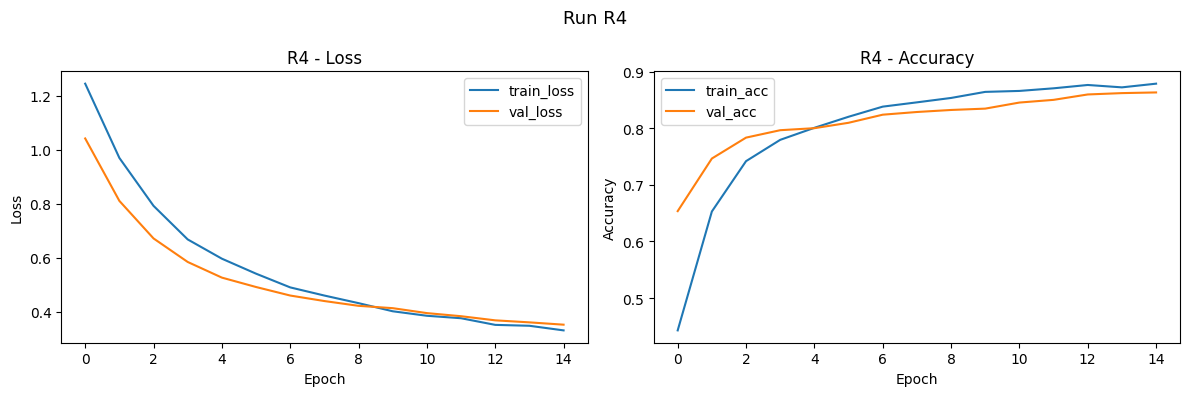

In [16]:
# Fine-tune EfficientNetB0 — unfreeze top layers at very low LR
print("R4 - Fine-tuning EfficientNetB0 (top ~20 layers)...")

model_r4, base_r4, target_r4 = build_model("efficientnetb0", freeze_base=False, learning_rate=1e-5)

# Freeze all but last ~20 layers of EfficientNet backbone
base_r4.trainable = True
for layer in base_r4.layers[:-20]:
    layer.trainable = False

model_r4.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model_r4.summary(show_trainable=True)

reset_gpu_mem()
cb_early_r4 = callbacks.EarlyStopping(
    monitor="val_loss", patience=PATIENCE, restore_best_weights=True, verbose=1
)
t0 = time.time()
history_r4 = model_r4.fit(
    train_ds, validation_data=val_ds,
    epochs=MAX_EPOCHS, callbacks=[cb_early_r4], verbose=1
)
t_total_r4 = time.time() - t0
record_r4 = log_run_metrics("R4", "EfficientNetB0", "finetune_top20layers_lr1e-5",
                             history_r4, model_r4, t_total_r4,
                             t_total_r4 / len(history_r4.history["val_loss"]))
plot_loss_curve(history_r4, "R4")

## 8 — Choose Best Model by Val Metrics

In [17]:
# Select the best model by best_val_loss
print("\n=== Run Summary ===")
print(f"{'Run':<5} {'Arch':<18} {'Strategy':<35} {'best_val_loss':<15} {'best_val_acc':<12}")
print("-" * 90)
for r in all_run_metrics:
    print(f"{r['run_id']:<5} {r['architecture']:<18} {r['strategy']:<35} "
          f"{r['best_val_loss']:<15.4f} {r['best_val_acc']:.4f}")

# Pick the best run (lowest val_loss)
best_record = min(all_run_metrics, key=lambda r: r["best_val_loss"])
print(f"\n-> Best run: {best_record['run_id']} ({best_record['architecture']} / {best_record['strategy']})")

run_to_model = {"R1": model_r1, "R2": model_r2, "R3": model_r3, "R4": model_r4}
run_to_target = {"R1": target_r1, "R2": target_r2, "R3": target_r3, "R4": target_r4}
final_model = run_to_model[best_record["run_id"]]
final_target_layer = run_to_target[best_record["run_id"]]
final_arch = best_record["architecture"]
print(f"   GradCAM target layer: {final_target_layer}")


=== Run Summary ===
Run   Arch               Strategy                            best_val_loss   best_val_acc
------------------------------------------------------------------------------------------
R1    resnet50           frozen_backbone                     0.2350          0.9262
R2    ResNet50           finetune_conv5block3_lr1e-5         0.1613          0.9512
R3    efficientnetb0     frozen_backbone                     0.5339          0.7940
R4    EfficientNetB0     finetune_top20layers_lr1e-5         0.3531          0.8631

-> Best run: R2 (ResNet50 / finetune_conv5block3_lr1e-5)
   GradCAM target layer: conv5_block3_out


## 9 — Final Model: Test-Set Evaluation (run ONCE)

Evaluating final model on test set (one time only)...
=== Final Model - Test Set ===
Accuracy: 0.8981
              precision    recall  f1-score   support

      glioma     0.9497    0.7550    0.8412       400
  meningioma     0.8281    0.8550    0.8413       400
     notumor     0.9343    0.9950    0.9637       400
   pituitary     0.8916    0.9875    0.9371       400

    accuracy                         0.8981      1600
   macro avg     0.9009    0.8981    0.8958      1600
weighted avg     0.9009    0.8981    0.8958      1600



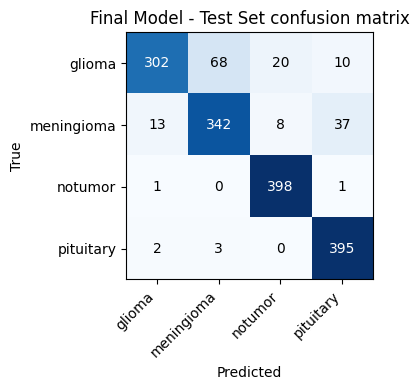


Test evaluation complete.


In [18]:
# Single test-set evaluation — evaluated ONCE on the chosen final model
print("Evaluating final model on test set (one time only)...")

y_true, y_pred = [], []
for x_batch, y_batch in test_ds:
    preds = final_model.predict(x_batch, verbose=0)
    y_true.extend(y_batch.numpy().tolist())
    y_pred.extend(np.argmax(preds, axis=1).tolist())

test_metrics = evaluate_predictions(y_true, y_pred, title="Final Model - Test Set")
plt.show()
print("\nTest evaluation complete.")

## 10 — Export Model

In [22]:
# Export final model
import os
os.makedirs("model", exist_ok=True)
MODEL_PATH = "model/model_T20.keras"
final_model.save(MODEL_PATH)

model_size_mb = os.path.getsize(MODEL_PATH) / 1024**2
print(f"Saved: {MODEL_PATH}  ({model_size_mb:.1f} MB)")
if model_size_mb > 100:
    print("WARNING: Model > 100 MB — GitHub will reject push. Tell Seif — fix: save in half precision.")
elif model_size_mb < 5:
    print("WARNING: Model < 5 MB — packaging will reject (too small / dummy model?).")
else:
    print("Model size OK.")

# Update size in best record
best_record["saved_model_size_mb"] = round(model_size_mb, 2)

# Verify load in same runtime (fresh-runtime test will be done manually)
loaded = tf.keras.models.load_model(MODEL_PATH)
test_input = tf.ones([1, IMAGE_SIZE, IMAGE_SIZE, 3])
out = loaded(test_input, training=False)
print(f"Load verification OK - output shape: {out.shape}, sum_probs={float(tf.reduce_sum(out)):.4f}")

Saved model: model/model_T20.keras
Model size: 124.8 MB


NameError: Exception encountered when calling Lambda.call().

[1mname 'applications' is not defined[0m

Arguments received by Lambda.call():
  • inputs=tf.Tensor(shape=(1, 224, 224, 3), dtype=float32)
  • mask=None
  • training=False

## 11 — Save Metrics JSON

In [ ]:
# Save metrics JSON
final_model_record = {
    "selected_run": best_record["run_id"],
    "test_accuracy": round(test_metrics["accuracy"], 6),
    "macro_precision": round(test_metrics["macro_precision"], 6),
    "macro_recall": round(test_metrics["macro_recall"], 6),
    "macro_f1": round(test_metrics["macro_f1"], 6),
    "per_class": test_metrics["per_class"],
    "confusion_matrix": test_metrics["confusion_matrix"],
    "gradcam_done": False,
    "model_file_mb": best_record["saved_model_size_mb"]
}

save_metrics_json(final_model_metrics=final_model_record)
print(json.dumps(final_model_record, indent=2))

## 12 — GradCAM via tf.GradientTape

In [ ]:
# GradCAM implementation (tf.GradientTape)
# Target layers: ResNet50 "conv5_block3_out" ; EfficientNetB0 "top_activation"

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    """
    img_array: (1, 224, 224, 3) float32 0..255
    Returns a (H, W) heatmap in [0, 1].
    """
    grad_model = None
    for layer in model.layers:
        if hasattr(layer, 'layers'):  # nested Model (the backbone)
            try:
                conv_layer = layer.get_layer(last_conv_layer_name)
                grad_model = tf.keras.Model(
                    inputs=model.inputs,
                    outputs=[conv_layer.output, model.output]
                )
                break
            except ValueError:
                continue

    if grad_model is None:
        raise ValueError(f"Could not find layer '{last_conv_layer_name}' in any sub-model.")

    with tf.GradientTape() as tape:
        inputs = tf.cast(img_array, tf.float32)
        conv_outputs, predictions = grad_model(inputs)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()


def overlay_gradcam(img_path, model, last_conv_layer_name, alpha=0.4):
    """Load image, run GradCAM, overlay heatmap."""
    import cv2
    img_raw = tf.io.read_file(img_path)
    img = tf.image.decode_image(img_raw, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMAGE_SIZE, IMAGE_SIZE])
    img_array = tf.cast(img, tf.float32)[tf.newaxis]  # (1,224,224,3)

    preds = model(img_array, training=False).numpy()[0]
    pred_idx = int(np.argmax(preds))
    pred_label = CLASSES[pred_idx]

    true_label = "unknown"
    for c in CLASSES:
        if f"/{c}/" in img_path or f"\\{c}\\" in img_path:
            true_label = c
            break

    heatmap = make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_idx)

    heatmap_resized = np.uint8(255 * heatmap)
    heatmap_colored = cv2.applyColorMap(cv2.resize(heatmap_resized,
                                                    (IMAGE_SIZE, IMAGE_SIZE)),
                                         cv2.COLORMAP_JET)
    heatmap_colored = cv2.cvtColor(heatmap_colored, cv2.COLOR_BGR2RGB)

    original = img.numpy().astype(np.uint8)
    superimposed = cv2.addWeighted(original, 1 - alpha, heatmap_colored, alpha, 0)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4))
    axes[0].imshow(original)
    axes[0].set_title(f"Original\nTrue: {true_label}")
    axes[0].axis('off')
    axes[1].imshow(superimposed)
    axes[1].set_title(f"GradCAM Overlay\nPred: {pred_label} ({preds[pred_idx]:.2%})")
    axes[1].axis('off')
    plt.suptitle(os.path.basename(img_path), fontsize=10)
    plt.tight_layout()
    plt.show()
    return fig, pred_label, true_label

print("GradCAM helpers ready.")

## 13 — Run GradCAM on Fixed 6 Test Images

In [ ]:
# Run GradCAM for all CELL G paths
print(f"Running GradCAM on {len(GRADCAM_TEST_PATHS)} images...")
print(f"Final model: {final_arch}  |  Target layer: {final_target_layer}")

misclassified_found = []
for img_path in GRADCAM_TEST_PATHS:
    if not os.path.exists(img_path):
        print(f"WARNING: Image not found: {img_path} - skipping.")
        continue
    fig, pred_label, true_label = overlay_gradcam(img_path, final_model, final_target_layer)
    if pred_label != true_label:
        misclassified_found.append({"path": img_path, "true": true_label, "pred": pred_label})
        print(f"  MISCLASSIFIED: true={true_label}, pred={pred_label}")

print(f"\nGradCAM done. Misclassified among test paths: {len(misclassified_found)}")

# Update metrics JSON to mark gradcam as done
final_model_record["gradcam_done"] = True
save_metrics_json(final_model_metrics=final_model_record)

## 14 — GradCAM Commentary

*(Fill in after running the notebook — 2-3 sentences per architecture)*

**ResNet50 GradCAM observations:**  
<!-- FILL: Which regions are highlighted? Tumor mass / ventricle / background? -->

**EfficientNetB0 GradCAM observations:**  
<!-- FILL: Which regions are highlighted? Do the two architectures differ? -->

**Comparison:**  
<!-- FILL: Contrast the two models' attention maps -->

## 15 — Version Info

In [ ]:
# Record exact TF/Keras versions (for report section 12)
import tensorflow as tf
import keras
import sklearn
print(f"TensorFlow : {tf.__version__}")
print(f"Keras      : {keras.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"NumPy      : {np.__version__}")
print(f"Python     : {__import__('sys').version}")

## 16 — Git Push Reminder

```bash
# From /content/t20-brain-tumor-detection/
git add notebooks/tensorflow_T20.ipynb results/metrics_tensorflow.json report/section_tensorflow.md model/model_T20.keras
git commit -m "tensorflow: R1-R4, final eval, GradCAM, final model"
git push
```

Then message Seif: **"done - final model = `model_T20.keras`, chosen run = `R_`, test acc = `X`"**

### Pre-push checklist
- [ ] Notebook has **all outputs saved** (run top-to-bottom, then Save)
- [ ] `model_T20.keras` > 5 MB and <= 100 MB
- [ ] `results/metrics_tensorflow.json` has no `null` values in R1-R4
- [ ] `report/section_tensorflow.md` has no `<!-- FILL -->` markers left
- [ ] GradCAM figures are visible in notebook output